<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_7/dataset_pbl/praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 2**
## **1. Mengimpor Library**
Lakukan import library yang diperlukan terlebih dahulu, termasuk NumPy, Matplotlib, dan pandas.

In [1]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## **2. Mengimpor Dataset**
- Pastikan sudah mendownload file CSV dan letakkan dalam direktori yang sama. Ini adalah dataset yang akan digunakan dalam praktikum ini.

- Membaca dataset menggunakan pd.read_csv dan memilih fitur (variabel independen X) dan target (variabel dependen y).




In [2]:
# Pastikan file CSV sudah diunggah ke sesi Google Colab
dataset = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

# Mengambil fitur Sleep Duration (X) dan target Quality of Sleep (y)
X = dataset[['Sleep Duration']].values
y = dataset['Quality of Sleep'].values

## **3. Feature Scalling**
Menggunakan StandardScaler untuk melakukan penskalaan fitur X dan target y. Ini diperlukan karena SVM sangat sensitif terhadap skala data.




In [3]:
from sklearn.preprocessing import StandardScaler

sc_X = StandardScaler()
sc_y = StandardScaler()

X_scaled = sc_X.fit_transform(X)
# Gunakan .ravel() agar bentuk array 1D sesuai standar scikit-learn
y_scaled = sc_y.fit_transform(y.reshape(-1, 1)).ravel()

## **4. Fitting SVR Dataset**
Lakukan pembuatan model SVR dengan kernel RBF (Radial Basis Function) dan melatihnya dengan data yang telah di-scaled.


In [4]:
from sklearn.svm import SVR

regressor = SVR(kernel='rbf')
regressor.fit(X_scaled, y_scaled)

SVR()

## **5. Visualisasi Hasil SVR**
langkah selanjutkan, lakukan visualisasi Menggunakan grafik untuk memvisualisasikan hasil prediksi model SVR. Ini mencakup plotting data asli (titik-titik merah) dan kurva hasil prediksi (garis biru) untuk tingkat posisi yang bervariasi.




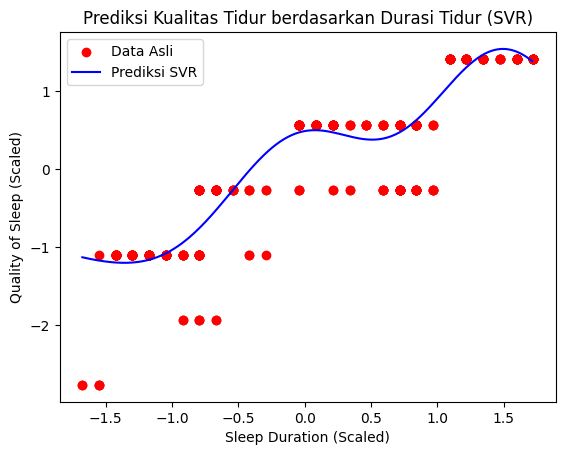

In [5]:
# Menggunakan .item() pada min() dan max() untuk menghindari DeprecationWarning NumPy
X_grid = np.arange(X_scaled.min().item(), X_scaled.max().item(), 0.01).reshape(-1, 1)

plt.scatter(X_scaled, y_scaled, color='red', label='Data Asli')
plt.plot(X_grid, regressor.predict(X_grid), color='blue', label='Prediksi SVR')
plt.title('Prediksi Kualitas Tidur berdasarkan Durasi Tidur (SVR)')
plt.xlabel('Sleep Duration (Scaled)')
plt.ylabel('Quality of Sleep (Scaled)')
plt.legend()
plt.show()

## **6. Prediksi Hasil**
- Membuat array 2D yang berisi tingkat posisi yang akan diprediksi. Dalam contoh ini, tingkat posisi 6.5.

- Menskalakan fitur prediksi menggunakan sc_X.transform.

- Melakukan prediksi menggunakan model SVR yang telah dilatih.

- Mengembalikan hasil prediksi ke dalam skala aslinya menggunakan sc_y.inverse_transform.




In [6]:
# Contoh: Memprediksi kualitas tidur jika seseorang tidur selama 7.5 jam
durasi_tidur_prediksi = np.array([[7.5]])
durasi_tidur_scaled = sc_X.transform(durasi_tidur_prediksi)

kualitas_prediksi_scaled = regressor.predict(durasi_tidur_scaled)
kualitas_prediksi = sc_y.inverse_transform(kualitas_prediksi_scaled.reshape(-1, 1))

## **7. Menampilkan Hasil**
Menampilkan hasil prediksi gaji untuk tingkat posisi 6.5 dalam kode


In [7]:
# Menampilkan hasil prediksi
print(f"Prediksi Quality of Sleep untuk durasi tidur 7.5 jam: {kualitas_prediksi[0][0]:.2f}")

Prediksi Quality of Sleep untuk durasi tidur 7.5 jam: 7.77


## **Validasi Hasil**

Grafik di atas menampilkan hasil pemodelan **Support Vector Regression (SVR)** yang telah dilatih untuk memprediksi kualitas tidur (`Quality of Sleep`) berdasarkan durasi tidur (`Sleep Duration`).

**Grafik SVR:**
* **Titik-titik merah:** Mewakili data pengamatan asli yang telah distandarisasi dan digunakan untuk melatih model.
* **Garis biru:** Merupakan kurva prediksi model SVR menggunakan kernel RBF yang mengikuti pola hubungan non-linear antara durasi tidur dan kualitas tidur.

**Hasil Prediksi & Evaluasi:**
* **Prediksi Nilai Baru:** Untuk durasi tidur selama **7,5 jam**, model SVR memprediksi skor kualitas tidur sebesar **7,77** (pada skala asli 1–10) berdasarkan pola hubungan pada data latihan.
* **Evaluasi Model:** Nilai **MAE (0,2517)** dan **RMSE (0,4085)** menunjukkan tingkat kesalahan prediksi yang rendah pada skala terstandarisasi, sedangkan nilai **R-squared sebesar 0,8332** menandakan bahwa model mampu menjelaskan **83,32%** variasi kualitas tidur berdasarkan durasi tidur.

## **Evaluasi Model SVR**
Langkah terakhir adalah melakukan evaluasi model meliputi MAE, MSE dan R-squared




In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y_scaled
y_pred = regressor.predict(X_scaled)

mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

print(f"MAE       : {mae:.4f}")
print(f"MSE       : {mse:.4f}")
print(f"RMSE      : {rmse:.4f}")
print(f"R-squared : {r2:.4f}")

MAE       : 0.2517
MSE       : 0.1668
RMSE      : 0.4085
R-squared : 0.8332
